# Exploratory Data Analysis — Home Credit Default Risk

**Goal**: understand the data before modelling and justify the features built in `scripts/preprocess.py`.

| # | Section |
|---|---|
| 1 | Setup, helper functions, data loading |
| 2 | Tables overview |
| 3 | The target |
| 4 | `application` table (quality, categoricals, numerics, external scores, age and ratios, drift) |
| 5 | Secondary tables (quick look) |
| 6 | Client-level aggregated features |
| 7 | Summary and decisions |

## 1. Setup and loading

### 1.1 Imports and paths

In [72]:
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 120)
pd.set_option("display.float_format", "{:,.4f}".format)

# The notebook can live in the project root or in scripts/feature_engineering
ROOT = Path.cwd().resolve()
if ROOT.name == "feature_engineering":
    ROOT = ROOT.parent.parent if ROOT.parent.name == "scripts" else ROOT.parent
DATA_DIR = Path(os.environ.get("CREDIT_DATA_DIR", ROOT / "data")).expanduser().resolve()
os.environ["CREDIT_DATA_DIR"] = str(DATA_DIR)
sys.path.insert(0, str(ROOT / "scripts"))

import preprocess as pp   # read, load_tables, clean_application, add_application_features, build_features

assert DATA_DIR.is_dir(), f"Data directory not found: {DATA_DIR}"

TARGET = "TARGET"
NROWS = None      # e.g. 200_000 to sample the 6 big secondary tables (application tables are always read in full)
BLUE, GREEN, RED = "#2a6fdb", "#2a9d8f", "#e63946"
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 120)
pd.set_option("display.float_format", "{:,.4f}".format)

ROOT = Path.cwd().resolve()
if ROOT.name == "feature_engineering":
    ROOT = ROOT.parent.parent if ROOT.parent.name == "scripts" else ROOT.parent

DATA_DIR = Path(os.environ.get("CREDIT_DATA_DIR", ROOT / "data")).expanduser().resolve()
os.environ["CREDIT_DATA_DIR"] = str(DATA_DIR)
sys.path.insert(0, str(ROOT / "scripts"))

import preprocess as pp

assert DATA_DIR.is_dir(), f"Data directory not found: {DATA_DIR}"

TARGET = "TARGET"
NROWS = None  # Set to 200_000 to limit secondary-table rows.
BLUE, GREEN, RED = "#2a6fdb", "#2a9d8f", "#e63946"

### 1.2 Helper functions

Every function used in the analysis lives here: the following sections only contain calls.

In [73]:
def univariate_auc(df, columns, target=TARGET, min_rows=500):
    """Calculate individual AUC scores and feature availability."""
    results = {}

    for col in columns:
        data = df[[col, target]].dropna()

        if len(data) >= min_rows and data[col].nunique() > 1:
            auc = roc_auc_score(data[target], data[col])

            results[col] = {
                "auc": max(auc, 1 - auc),
                "auc_raw": auc,
                "available_%": len(data) / len(df) * 100,
            }

    return pd.DataFrame.from_dict(results, orient="index").sort_values(
        "auc", ascending=False
    )


def cramers_v_table(df, columns, target=TARGET):
    """Measure categorical feature association with the target using Cramér's V."""
    results = []

    for col in columns:
        table = pd.crosstab(df[col].fillna("Missing"), df[target])
        chi2, p_value, _, _ = stats.chi2_contingency(table)

        denominator = table.values.sum() * (min(table.shape) - 1)
        cramers_v = np.sqrt(chi2 / denominator) if denominator > 0 else np.nan

        results.append({
            "column": col,
            "categories": table.shape[0],
            "p_value": p_value,
            "cramers_v": cramers_v,
        })

    return pd.DataFrame(results).sort_values(
        "cramers_v", ascending=False
    )


def plot_default_by_category(df, col, top=12, ax=None):
    """Plot default rates for the most frequent categories."""
    grouped = (
        df.groupby(df[col].fillna("Missing"))[TARGET]
        .agg(["mean", "size"])
        .sort_values("size", ascending=False)
        .head(top)
    )

    ax = ax or plt.gca()
    rates = grouped["mean"] * 100

    sns.barplot(x=rates, y=grouped.index.astype(str), ax=ax, color=BLUE)

    for i, (rate, count) in enumerate(zip(rates, grouped["size"])):
        ax.text(rate, i, f"  {rate:.1f}% (n={count:,})", va="center", fontsize=8)

    ax.axvline(df[TARGET].mean() * 100, color=RED, linestyle="--", linewidth=1)
    ax.set(title=col, xlabel="Default rate (%)", ylabel="")


def plot_default_by_bins(df, col, bins=None, q=None, ax=None):
    """Plot default rates across fixed-width bins or quantile groups."""
    data = df[[col, TARGET]].dropna()

    groups = (
        pd.cut(data[col], bins=bins)
        if bins is not None
        else pd.qcut(data[col], q=q, duplicates="drop")
    )

    rates = data.groupby(groups, observed=True)[TARGET].mean() * 100

    ax = ax or plt.gca()
    ax.bar(range(len(rates)), rates.values, color=BLUE)
    ax.set_xticks(range(len(rates)))
    ax.set_xticklabels(
        [str(interval) for interval in rates.index],
        rotation=45,
        ha="right",
        fontsize=8,
    )

    ax.axhline(df[TARGET].mean() * 100, color=RED, linestyle="--", linewidth=1)
    ax.set(title=f"Default rate by {col} bin", ylabel="Default rate (%)")


def plot_missing(df, top=40):
    """Plot the most incomplete columns and return all missing-value percentages."""
    missing = (df.isna().mean() * 100).sort_values(ascending=False)
    missing = missing[missing > 0]

    missing.head(top).sort_values().plot.barh(
        figsize=(8, max(4, min(top, len(missing)) * 0.22)),
        color=BLUE,
    )

    plt.title(f"Missing values (top {top})")
    plt.xlabel("Missing values (%)")
    plt.tight_layout()
    plt.show()

    return missing


def plot_kde_by_target(df, columns):
    """Compare feature distributions for repaid (0) and defaulted (1) clients."""
    fig, axes = plt.subplots(
        1,
        len(columns),
        figsize=(5 * len(columns), 3.5),
        squeeze=False,
    )

    for ax, col in zip(axes.ravel(), columns):
        for target_value, color in [(0, GREEN), (1, RED)]:
            values = df.loc[df[TARGET] == target_value, col].dropna()

            if not values.empty and values.nunique() > 1:
                sns.kdeplot(
                    values,
                    ax=ax,
                    color=color,
                    fill=True,
                    alpha=0.25,
                    label=f"TARGET={target_value}",
                )

        ax.set_title(col)
        ax.legend()

    plt.tight_layout()
    plt.show()

### 1.3 Loading the tables

In [74]:
T = pp.load_tables(NROWS)
app_train, app_test = T["application_train"], T["application_test"]
bureau, bb, prev = T["bureau"], T["bureau_balance"], T["previous_application"]
pos, cc, ins = T["POS_CASH_balance"], T["credit_card_balance"], T["installments_payments"]
app_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,...,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,"202,500.0000","406,597.5000","24,700.5000","351,000.0000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0188,-9461,-637,"-3,648.0000",-2120,NaN,1,1,0,1,1,0,Laborers,1.0000,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.0830,0.2629,0.1394,0.0247,0.0369,0.9722,0.6192,0.0143,0.0000,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,...,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.0220,0.0198,0.0000,0.0000,0.0250,0.0369,0.9722,0.6243,0.0144,0.0000,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.0000,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0000,2.0000,2.0000,2.0000,"-1,134.0000",0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000
1,100003,0,Cash loans,F,N,N,0,"270,000.0000","1,293,502.5000","35,698.5000","1,129,500.0000",Family,State servant,Higher education,Married,House / apartment,0.0035,-16765,-1188,"-1,186.0000",-291,NaN,1,1,0,1,1,0,Core staff,2.0000,1,1,MONDAY,11,0,0,0,0,0,0,School,0.3113,0.6222,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.0800,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,...,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.0790,0.0554,0.0000,0.0000,0.0968,0.0529,0.9851,0.7987,0.0608,0.0800,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.0100,reg oper account,block of flats,0.0714,Block,No,1.0000,0.0000,1.0000,0.0000,-828.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,100004,0,Revolving loans,M,Y,Y,0,"67,500.0000","135,000.0000","6,750.0000","135,000.0000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0100,-19046,-225,"-4,260.0000",-2531,26.0000,1,1,1,1,1,0,Laborers,1.0000,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.5559,0.7296,NaN,NaN

## 2. Tables overview

In [75]:
# Size, memory and missing rate of each table
overview = pd.DataFrame({
    name: {
        "rows": len(df),
        "columns": df.shape[1],
        "memory_MB": df.memory_usage(deep=True).sum() / 1e6,
        "missing_%": df.isna().mean().mean() * 100,
        "unique_clients": df["SK_ID_CURR"].nunique() if "SK_ID_CURR" in df else np.nan,
    }
    for name, df in T.items()
}).T
overview

,rows,columns,memory_MB,missing_%,unique_clients
application_train,"307,511.0000",122.0000,364.9971,24.3959,"307,511.0000"
application_test,"48,744.0000",121.0000,57.8273,23.8117,"48,744.0000"
bureau,"1,716,428.0000",17.0000,401.3892,13.5026,"305,811.0000"
bureau_balance,"27,299,925.0000",3.0000,"1,610.6957",0.0000,NaN
previous_application,"1,670,214.0000",37.0000,"1,645.4374",17.9769,"338,857.0000"
POS_CASH_balance,"10,001,358.0000",8.0000,842.4457,0.0652,"337,252.0000"
credit_card_balance,"3,840,312.0000",23.0000,545.7148,6.6541,"103,558.0000"
installments_payments,"13,605,401.0000",8.0000,517.0054,0.0053,"339,587.0000"


In [76]:
# Share of train/test clients present in each secondary table
ids = {
    name: T[name]["SK_ID_CURR"]
    for name in [
        "bureau",
        "previous_application",
        "POS_CASH_balance",
        "credit_card_balance",
        "installments_payments",
    ]
}

# bureau_balance has no SK_ID_CURR, so retrieve client IDs through bureau.
bb_clients = bureau.loc[
    bureau["SK_ID_BUREAU"].isin(bb["SK_ID_BUREAU"].unique()),
    "SK_ID_CURR",
]
ids["bureau_balance (via bureau)"] = bb_clients

coverage = pd.DataFrame({
    name: {
        "train_%": app_train["SK_ID_CURR"].isin(client_ids).mean() * 100,
        "test_%": app_test["SK_ID_CURR"].isin(client_ids).mean() * 100,
    }
    for name, client_ids in ids.items()
}).T

display(coverage)

# Check for client IDs shared between train and test.
shared = set(app_train["SK_ID_CURR"]) & set(app_test["SK_ID_CURR"])
print(f"Clients shared by train and test: {len(shared)} (expected: 0)")

,train_%,test_%
bureau,85.6851,86.8209
previous_application,94.6493,98.0634
POS_CASH_balance,94.1248,98.0798
credit_card_balance,28.2608,34.1642
installments_payments,94.8399,98.3588
bureau_balance (via bureau),29.9927,86.8025


Clients shared by train and test: 0 (expected: 0)


Secondary tables do not cover every client: aggregates will be **NaN** for clients without history (which is informative in itself).

## 3. The target

TARGET
0    282686
1     24825
Default rate: 8.07% | accuracy of always predicting 0: 91.93%


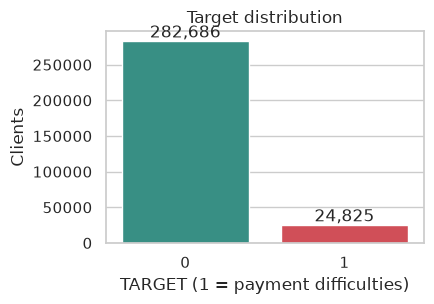

In [77]:
counts = app_train[TARGET].value_counts().sort_index()
default_rate = app_train[TARGET].mean()
print(counts.to_string())
print(f"Default rate: {default_rate:.2%} | accuracy of always predicting 0: {1 - default_rate:.2%}")

fig, ax = plt.subplots(figsize=(4.5, 3.2))
sns.barplot(x=counts.index.astype(str), y=counts.values, hue=counts.index.astype(str),
            palette=[GREEN, RED], legend=False, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set(title="Target distribution", xlabel="TARGET (1 = payment difficulties)", ylabel="Clients")
plt.tight_layout(); plt.show()

Classes are **highly imbalanced** (~8 % defaults): accuracy is misleading. We use **AUC** (and PR-AUC) with **stratified** splits.

## 4. `application` table (train / test)

### 4.1 Structure and missing values

TARGET
0    282686
1     24825
Default rate: 8.07% | Accuracy of always predicting 0: 91.93%


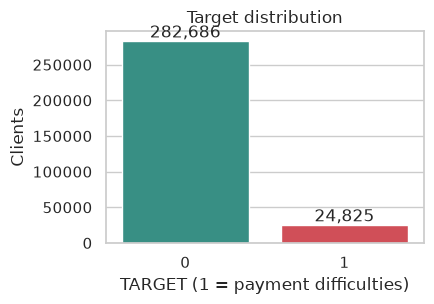

In [78]:
# Target distribution and baseline accuracy
counts = app_train[TARGET].value_counts().sort_index()
default_rate = app_train[TARGET].mean()

print(counts.to_string())
print(
    f"Default rate: {default_rate:.2%} | "
    f"Accuracy of always predicting 0: {1 - default_rate:.2%}"
)

fig, ax = plt.subplots(figsize=(4.5, 3.2))

sns.barplot(
    x=counts.index.astype(str),
    y=counts.values,
    hue=counts.index.astype(str),
    palette=[GREEN, RED],
    legend=False,
    ax=ax,
)

for i, count in enumerate(counts.values):
    ax.text(i, count, f"{count:,}", ha="center", va="bottom")

ax.set(
    title="Target distribution",
    xlabel="TARGET (1 = payment difficulties)",
    ylabel="Clients",
)

plt.tight_layout()
plt.show()

In [79]:
# Check whether housing-related columns are missing together and whether this is informative.
housing = [
    col for col in app_train.columns
    if col.endswith(("_AVG", "_MODE", "_MEDI"))
]

no_housing_info = app_train[housing].isna().all(axis=1)

print(
    f"{len(housing)} housing columns | "
    f"All missing for {no_housing_info.mean():.1%} of clients"
)

housing_missing_stats = (
    app_train.groupby(no_housing_info)[TARGET]
    .agg(default_rate="mean", count="size")
    .rename_axis("housing_info_missing")
)

display(housing_missing_stats)

47 housing columns | All missing for 47.4% of clients


,default_rate,count
housing_info_missing,,
False,0.0700,161756
True,0.0926,145755


### 4.2 Anomalies and outliers

In [80]:
# Inspect special values, outliers, and suspicious data points.
placeholder = app_train["DAYS_EMPLOYED"] == 365243

print(
    f"DAYS_EMPLOYED = 365243: {placeholder.sum():,} rows "
    f"({placeholder.mean():.1%})"
)
print(
    f"Default rate: {app_train.loc[placeholder, TARGET].mean():.2%} "
    f"vs {app_train.loc[~placeholder, TARGET].mean():.2%} otherwise"
)
print(
    "Top income types among affected clients:",
    app_train.loc[placeholder, "NAME_INCOME_TYPE"]
    .value_counts()
    .head(3)
    .to_dict(),
)

print(
    "CODE_GENDER = XNA:",
    (app_train["CODE_GENDER"] == "XNA").sum(),
    "rows",
)

print(
    f"Income: max {app_train['AMT_INCOME_TOTAL'].max():,.0f} | "
    f"median {app_train['AMT_INCOME_TOTAL'].median():,.0f}"
)
print(
    f"Children: max {app_train['CNT_CHILDREN'].max()} | "
    f"max car age: {app_train['OWN_CAR_AGE'].max()}"
)

# Inspect extreme values in selected count variables.
for col in ["OBS_30_CNT_SOCIAL_CIRCLE", "AMT_REQ_CREDIT_BUREAU_QRT"]:
    print(
        f"{col}: max {app_train[col].max()} | "
        f"99th percentile {app_train[col].quantile(0.99)}"
    )

DAYS_EMPLOYED = 365243: 55,374 rows (18.0%)
Default rate: 5.40% vs 8.66% otherwise
Top income types among affected clients: {'Pensioner': 55352, 'Unemployed': 22}
CODE_GENDER = XNA: 4 rows
Income: max 117,000,000 | median 147,150
Children: max 19 | max car age: 91.0
OBS_30_CNT_SOCIAL_CIRCLE: max 348.0 | 99th percentile 10.0
AMT_REQ_CREDIT_BUREAU_QRT: max 261.0 | 99th percentile 2.0


**Decisions** (in `pp.clean_application`):
- `DAYS_EMPLOYED = 365243` (≈ 1000 years, a placeholder for pensioners / unemployed) → `NaN` + `DAYS_EMPLOYED_ANOM` flag;
- `CODE_GENDER = XNA` → `NaN`;
- extreme incomes are kept (trees are robust to them); the ratios normalise them.

### 4.3 Categorical variables and default

,column,categories,p_value,cramers_v
9,OCCUPATION_TYPE,19,0.0000,0.0801
11,ORGANIZATION_TYPE,58,0.0000,0.0723
5,NAME_INCOME_TYPE,8,0.0000,0.0638
6,NAME_EDUCATION_TYPE,5,0.0000,0.0576
1,CODE_GENDER,3,0.0000,0.0547
14,WALLSMATERIAL_MODE,8,0.0000,0.0441
15,EMERGENCYSTATE_MODE,3,0.0000,0.0422
13,HOUSETYPE_MODE,4,0.0000,0.0407
7,NAME_FAMILY_STATUS,6,0.0000,0.0405
8,NAME_HOUSING_TYPE,6,0.0000,0.0370


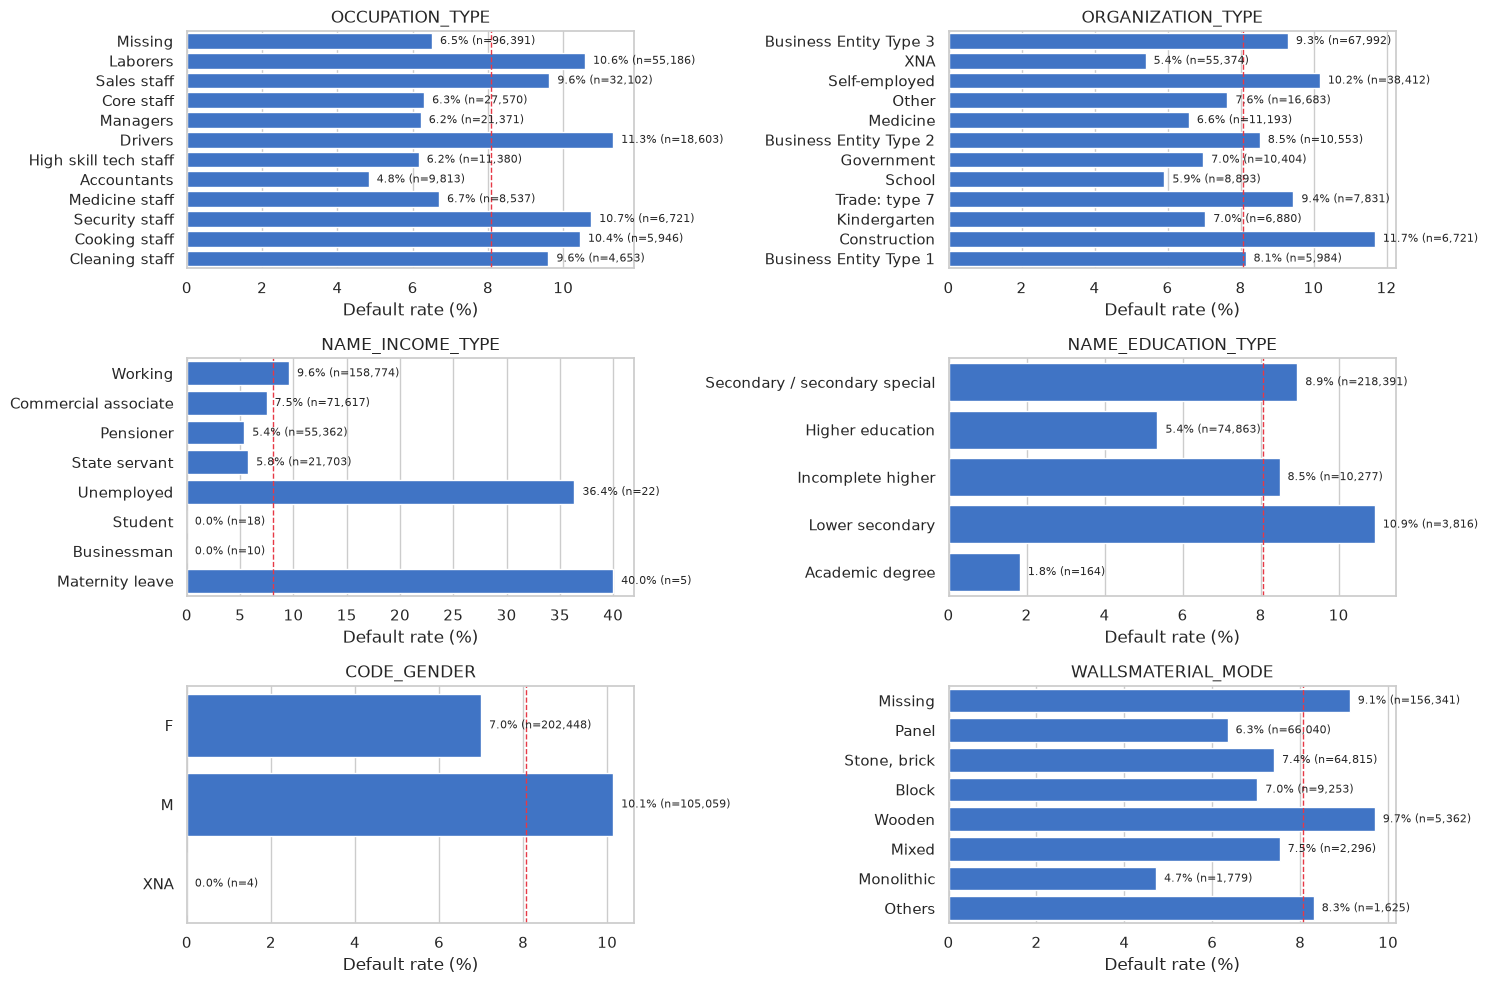

In [81]:
# Rank categorical features by their association with the target.
cramers = cramers_v_table(app_train, cat_cols)
display(cramers)

# Plot default rates for the six most strongly associated features.
top_features = cramers["column"].head(6)

fig, axes = plt.subplots(3, 2, figsize=(15, 10))

for ax, col in zip(axes.ravel(), top_features):
    plot_default_by_category(app_train, col, ax=ax)

plt.tight_layout()
plt.show()

Links are modest but real (income type, education, occupation, organisation type). `ORGANIZATION_TYPE` and `OCCUPATION_TYPE` have many categories: one-hot encoding is reasonable (out-of-fold target encoding is a possible improvement).

### 4.4 Numeric variables and target

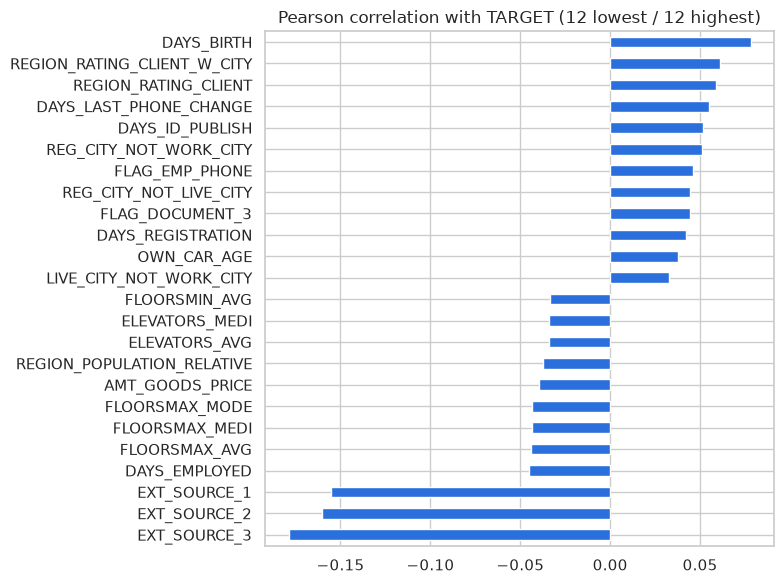

,auc,auc_raw,available_%
EXT_SOURCE_3,0.6794,0.3206,80.1747
EXT_SOURCE_1,0.6657,0.3343,43.6189
EXT_SOURCE_2,0.6561,0.3439,99.7854
DAYS_BIRTH,0.5830,0.5830,100.0000
OWN_CAR_AGE,0.5589,0.5589,34.0092
DAYS_LAST_PHONE_CHANGE,0.5569,0.5569,99.9997
DAYS_ID_PUBLISH,0.5557,0.5557,100.0000
FLOORSMAX_AVG,0.5504,0.4496,50.2392
FLOORSMAX_MEDI,0.5500,0.4500,50.2392
REGION_RATING_CLIENT_W_CITY,0.5492,0.5492,100.0000


In [82]:
# Build application features using preprocess.py as the single source of truth.
app_fe = pp.add_application_features(
    pp.clean_application(app_train)
)

# Rank numerical features by Pearson correlation with the target.
corr = (
    app_train[num_cols + [TARGET]]
    .corr()[TARGET]
    .drop(TARGET)
    .dropna()
    .sort_values()
)

pd.concat([corr.head(12), corr.tail(12)]).plot.barh(
    figsize=(8, 6),
    color=BLUE,
)

plt.title("Pearson correlation with TARGET (12 lowest / 12 highest)")
plt.tight_layout()
plt.show()

# Rank numerical features by individual predictive power (AUC).
auc_raw = univariate_auc(app_train, num_cols)
display(auc_raw.head(15))

`auc_raw` < 0.5 means the variable is *negatively* linked to default (e.g. `EXT_SOURCE`: the higher, the fewer defaults). No raw variable exceeds ~0.6 on its own: we need to **combine** them (ratios, aggregates).

### 4.5 External scores `EXT_SOURCE_1/2/3`

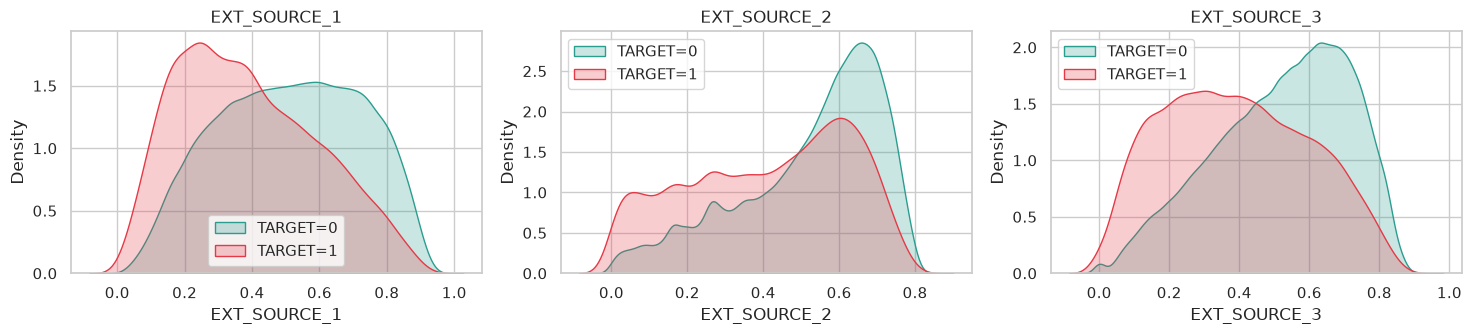

Correlation between external scores:


,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3
EXT_SOURCE_1,1.0000,0.2140,0.1870
EXT_SOURCE_2,0.2140,1.0000,0.1090
EXT_SOURCE_3,0.1870,0.1090,1.0000


,auc,auc_raw,available_%
EXT_WEIGHTED,0.7401,0.2599,35.6374
EXT_MEAN,0.7165,0.2835,99.9441
EXT_MIN,0.6910,0.3090,99.9441
EXT_MAX,0.6862,0.3138,99.9441
EXT_SOURCE_3,0.6794,0.3206,80.1747
EXT_PROD,0.6701,0.3299,100.0000
EXT_SOURCE_1,0.6657,0.3343,43.6189
EXT_SOURCE_2,0.6561,0.3439,99.7854
EXT_STD,0.5486,0.5486,87.9975


In [83]:
# External credit scores and engineered features.
ext = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]

ext_engineered = [
    "EXT_MEAN",
    "EXT_MIN",
    "EXT_MAX",
    "EXT_STD",
    "EXT_PROD",
    "EXT_WEIGHTED",
]

# Compare score distributions between repaid and defaulted clients.
plot_kde_by_target(app_fe, ext)

# Check correlations between the original external scores.
print("Correlation between external scores:")
display(app_fe[ext].corr().round(3))

# Compare the predictive power of original and engineered scores.
display(univariate_auc(app_fe, ext + ext_engineered))

The 3 scores are the best individual predictors and are **weakly correlated with each other**: their mean, min, product… add extra signal. We also build interactions with the credit term and age.

### 4.6 Age, employment length and business ratios

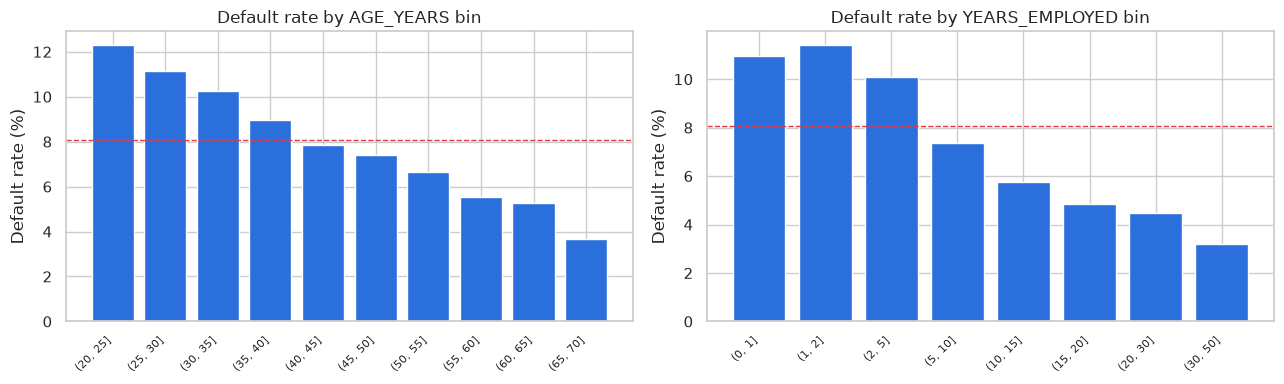

In [84]:
# Compare default rates by age and employment duration.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

plot_default_by_bins(
    app_fe,
    "AGE_YEARS",
    bins=np.arange(20, 71, 5),
    ax=axes[0],
)

plot_default_by_bins(
    app_fe,
    "YEARS_EMPLOYED",
    bins=[0, 1, 2, 5, 10, 15, 20, 30, 50],
    ax=axes[1],
)

plt.tight_layout()
plt.show()

,auc,auc_raw,available_%
AGE_YEARS,0.5830,0.4170,100.0000
YEARS_EMPLOYED,0.5824,0.4176,81.9928
DAYS_EMPLOYED_PERC,0.5697,0.4303,81.9928
CREDIT_GOODS_RATIO,0.5692,0.5692,99.9096
CREDIT_TERM,0.5321,0.5321,99.9961
ANNUITY_INCOME_RATIO,0.5195,0.5195,99.9961
CREDIT_INCOME_RATIO,0.5019,0.4981,100.0000


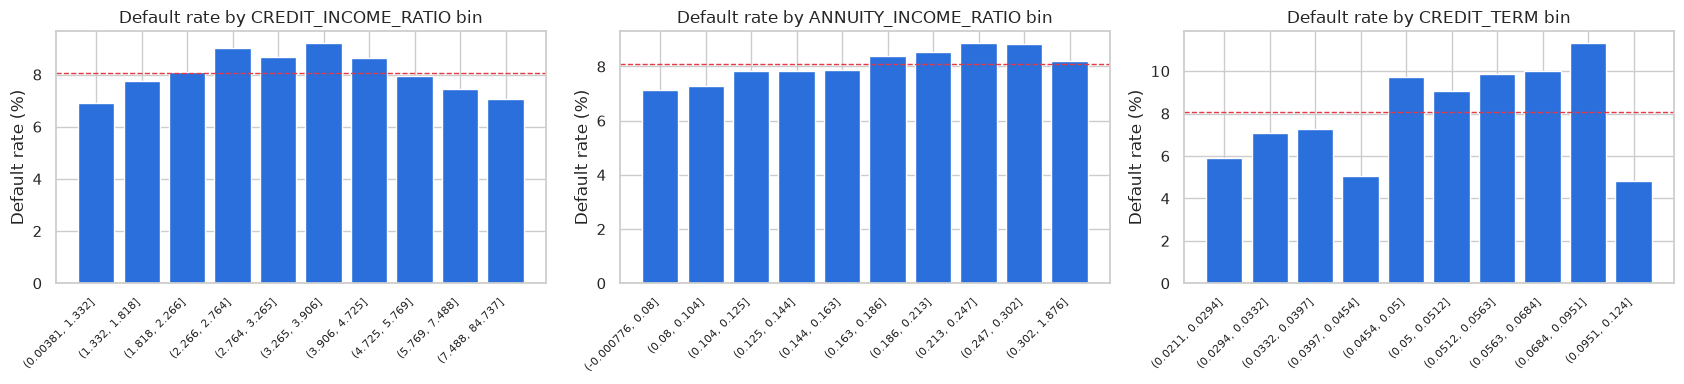

In [85]:
# Evaluate engineered financial ratios and demographic features.
ratios = [
    "CREDIT_INCOME_RATIO",
    "ANNUITY_INCOME_RATIO",
    "CREDIT_TERM",
    "CREDIT_GOODS_RATIO",
    "DAYS_EMPLOYED_PERC",
    "AGE_YEARS",
    "YEARS_EMPLOYED",
]

display(univariate_auc(app_fe, ratios))

# Plot default rates by decile for the three repayment-capacity ratios.
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

for ax, col in zip(axes, ratios[:3]):
    plot_default_by_bins(app_fe, col, q=10, ax=ax)

plt.tight_layout()
plt.show()

Risk **drops clearly with age** and employment length (monotonic; young clients default 2–3× more than those over 55). `CREDIT_TERM` and the effort ratios discriminate better than their raw components: we keep them.

### 4.7 Train / test drift

In [86]:
# Compare train/test numerical feature distributions using the KS statistic.
train_sample = app_train.sample(
    n=min(50_000, len(app_train)),
    random_state=0,
)
test_sample = app_test.sample(
    n=min(50_000, len(app_test)),
    random_state=0,
)

ks = pd.Series({
    col: stats.ks_2samp(
        train_sample[col].dropna(),
        test_sample[col].dropna(),
    ).statistic
    for col in num_cols
    if train_sample[col].notna().sum() > 50
    and test_sample[col].notna().sum() > 50
}).sort_values(ascending=False)

display(ks.head(8).to_frame("KS"))

print(f"Maximum KS statistic: {ks.max():.3f}")

,KS
AMT_REQ_CREDIT_BUREAU_QRT,0.2577
AMT_REQ_CREDIT_BUREAU_MON,0.1563
AMT_CREDIT,0.1152
AMT_GOODS_PRICE,0.1123
FLAG_EMAIL,0.1055
FLAG_DOCUMENT_3,0.0797
DAYS_LAST_PHONE_CHANGE,0.0699
AMT_ANNUITY,0.0599


Maximum KS statistic: 0.258


No notable drift: a stratified random validation split on train is representative of test.

## 5. Secondary tables (quick look)

Detailed aggregates are evaluated in section 6; here we only spot structure and anomalies to handle.

In [87]:
# Summarize the number of historical records per client in each table.
history_tables = {
    "bureau": bureau,
    "previous": prev,
    "pos_cash": pos,
    "credit_card": cc,
    "installments": ins,
}

rows_per_client = pd.DataFrame({
    name: df.groupby("SK_ID_CURR").size().describe()
    for name, df in history_tables.items()
}).T

display(rows_per_client)

,count,mean,std,min,25%,50%,75%,max
bureau,"305,811.0000",5.6127,4.4304,1.0000,2.0000,4.0000,8.0000,116.0000
previous,"338,857.0000",4.9290,4.2207,1.0000,2.0000,4.0000,7.0000,77.0000
pos_cash,"337,252.0000",29.6554,24.5320,1.0000,12.0000,22.0000,39.0000,295.0000
credit_card,"103,558.0000",37.0837,33.4836,1.0000,10.0000,22.0000,75.0000,192.0000
installments,"339,587.0000",40.0646,41.0533,1.0000,12.0000,25.0000,51.0000,372.0000


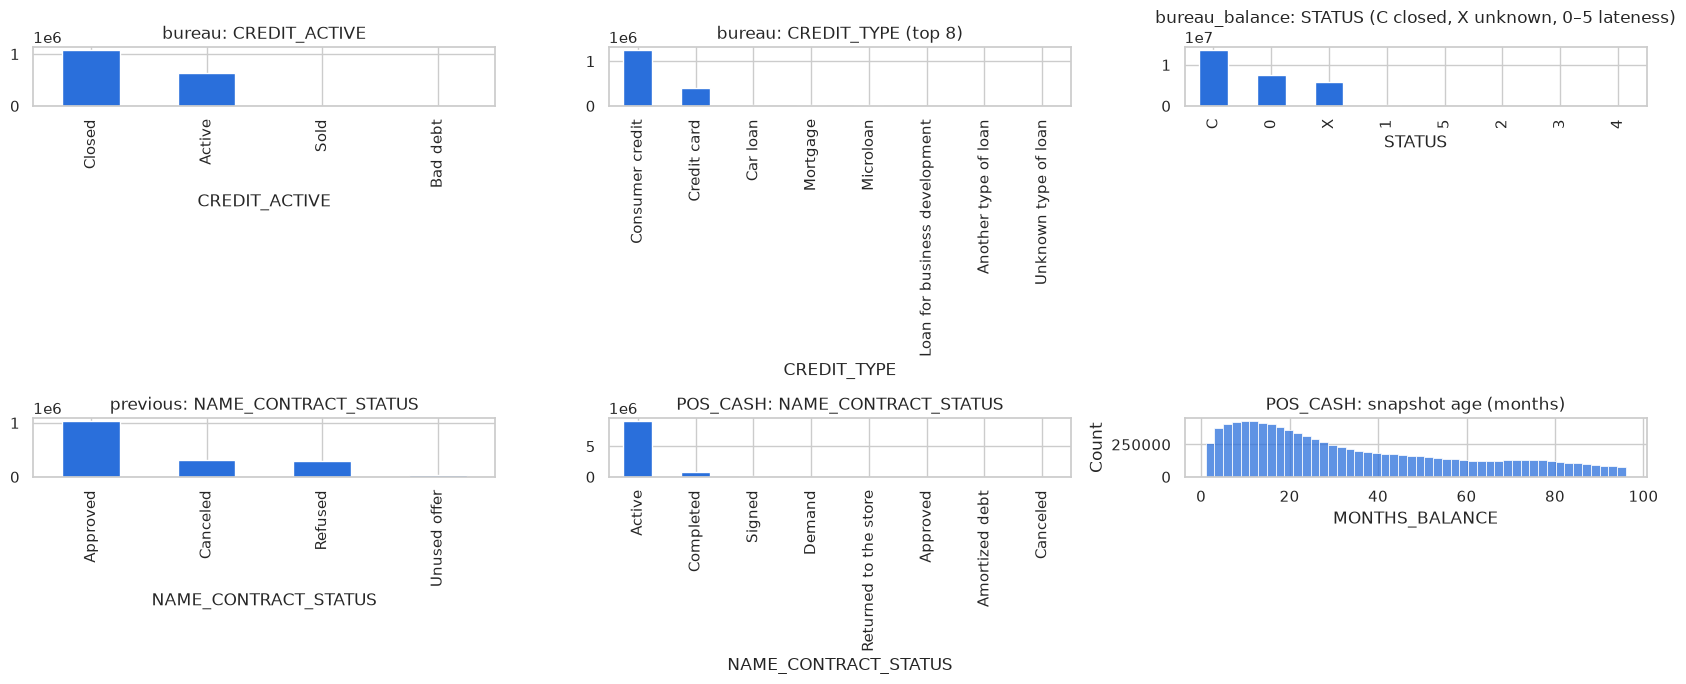

In [88]:
# Visualize the main categories and historical snapshot distribution.
panels = [
    (bureau["CREDIT_ACTIVE"], "bureau: CREDIT_ACTIVE"),
    (bureau["CREDIT_TYPE"], "bureau: CREDIT_TYPE (top 8)"),
    (bb["STATUS"], "bureau_balance: STATUS (C closed, X unknown, 0–5 lateness)"),
    (prev["NAME_CONTRACT_STATUS"], "previous: NAME_CONTRACT_STATUS"),
    (pos["NAME_CONTRACT_STATUS"], "POS_CASH: NAME_CONTRACT_STATUS"),
]

fig, axes = plt.subplots(2, 3, figsize=(17, 7))

# Plot the most frequent categories in each history table.
for ax, (series, title) in zip(axes.ravel(), panels):
    series.value_counts().head(8).plot.bar(
        ax=ax,
        title=title,
        color=BLUE,
    )

# Show the age of POS_CASH historical snapshots in months.
sns.histplot(
    -pos["MONTHS_BALANCE"],
    bins=48,
    ax=axes[1, 2],
    color=BLUE,
)

axes[1, 2].set_title("POS_CASH: snapshot age (months)")

plt.tight_layout()
plt.show()

In [89]:
# Identify anomalies and potential signals for feature engineering.

# Installment payment behavior.
days_late = (
    ins["DAYS_ENTRY_PAYMENT"] - ins["DAYS_INSTALMENT"]
).clip(lower=0)

underpaid = (
    ins["AMT_INSTALMENT"] - ins["AMT_PAYMENT"]
) > 0.01

# Credit card utilization, excluding invalid divisions.
utilisation = (
    cc["AMT_BALANCE"] / cc["AMT_CREDIT_LIMIT_ACTUAL"]
).replace([np.inf, -np.inf], np.nan)

# Special placeholder values in previous applications.
placeholder_cols = [
    "DAYS_FIRST_DRAWING",
    "DAYS_FIRST_DUE",
    "DAYS_LAST_DUE_1ST_VERSION",
    "DAYS_LAST_DUE",
    "DAYS_TERMINATION",
]

placeholders = {
    col: int((prev[col] == 365243).sum())
    for col in placeholder_cols
}

print("Previous applications — 365243 placeholders:", placeholders)

# POS_CASH payment difficulties.
print(
    f"POS_CASH — rows with SK_DPD > 0: "
    f"{(pos['SK_DPD'] > 0).mean():.2%}"
)

# Installment delays, underpayments, and missing payment dates.
print(
    f"Installments — late: {(days_late > 0).mean():.1%} | "
    f"underpaid: {underpaid.mean():.1%} | "
    f"no payment date: {ins['DAYS_ENTRY_PAYMENT'].isna().mean():.2%}"
)

# Credit card utilization and client coverage.
print(
    f"Credit card — {cc['SK_ID_CURR'].nunique():,} clients | "
    f"median utilization: {utilisation.median():.2f}"
)

# Compare missing-value percentages in secondary tables.
missing_secondary = pd.concat({
    "bureau": bureau.isna().mean(),
    "credit_card": cc.isna().mean(),
}).mul(100)

print("\nMost incomplete columns (%):")
print(
    missing_secondary.sort_values(ascending=False)
    .head(8)
    .round(1)
    .to_string()
)

Previous applications — 365243 placeholders: {'DAYS_FIRST_DRAWING': 934444, 'DAYS_FIRST_DUE': 40645, 'DAYS_LAST_DUE_1ST_VERSION': 93864, 'DAYS_LAST_DUE': 211221, 'DAYS_TERMINATION': 225913}
POS_CASH — rows with SK_DPD > 0: 2.95%
Installments — late: 8.4% | underpaid: 9.5% | no payment date: 0.02%
Credit card — 103,558 clients | median utilization: 0.01

Most incomplete columns (%):
bureau       AMT_ANNUITY                  71.5000
             AMT_CREDIT_MAX_OVERDUE       65.5000
             DAYS_ENDDATE_FACT            36.9000
             AMT_CREDIT_SUM_LIMIT         34.5000
credit_card  AMT_PAYMENT_CURRENT          20.0000
             AMT_DRAWINGS_OTHER_CURRENT   19.5000
             AMT_DRAWINGS_POS_CURRENT     19.5000
             CNT_DRAWINGS_ATM_CURRENT     19.5000


- The `365243` values in `previous_application` are placeholders → `NaN` (same as in `application`).
- Delinquencies (`SK_DPD`, `DPD`), active credits, past refusals and card utilisation are the signals to aggregate per client.
- Clients without a card or history stay `NaN`: a missing `*_COUNT` is itself informative.

## 6. Client-level aggregated features (`pp.build_features`)

The full pipeline runs once (result cached in `data/features.pkl`), then each feature is scored by its univariate AUC.

In [90]:
# Build train/test features using preprocess.py.
train_f, test_f = pp.build_features()

# Exclude identifiers and the target from the feature set.
feats = [
    col for col in train_f.columns
    if col not in ("SK_ID_CURR", TARGET)
]

# Assign each feature to its source table based on its prefix.
prefixes = {
    "BUREAU_": "bureau",
    "PREV_": "previous",
    "POS_": "pos_cash",
    "CC_": "credit_card",
    "INS_": "installments",
}

family = pd.Series({
    col: next(
        (name for prefix, name in prefixes.items() if col.startswith(prefix)),
        "application",
    )
    for col in feats
})

print(f"Train shape: {train_f.shape} | Test shape: {test_f.shape}")

display(
    family.value_counts()
    .rename("n_features")
    .to_frame()
)

Train shape: (307511, 876) | Test shape: (48744, 875)


,n_features
application,273
previous,253
bureau,197
credit_card,98
installments,31
pos_cash,22


In [ ]:
# Evaluate individual feature predictive power.
ua = univariate_auc(train_f, feats, min_rows=1000)
ua["family"] = family.reindex(ua.index)

display(ua.head(25))

# Compare predictive power and data completeness across feature families.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

ua.groupby("family")["auc"].agg(["max", "mean"]).sort_values("max").plot.barh(
    ax=axes[0],
    title="Univariate AUC by family",
)

fill_rate = (
    train_f[feats].notna().mean()
    .groupby(family)
    .mean()
    .sort_values()
    * 100
)

fill_rate.plot.barh(
    ax=axes[1],
    color=GREEN,
    title="Average fill rate by family (%)",
)

plt.tight_layout()
plt.show()

# Count features with more than 95% missing values.
sparse_features = (train_f[feats].notna().mean() < 0.05).sum()
print(f"Features with more than 95% NaN: {sparse_features}")

External scores dominate, followed by past payment delinquencies (installments, POS, bureau). History families have a lower fill rate but a strong signal when present.

## 7. Summary and feature-engineering decisions

| Finding | Decision (in `preprocess.py`) |
|---|---|
| ~8 % defaults, imbalanced classes | **AUC** metric (+ PR-AUC), **stratified** splits, never accuracy |
| `DAYS_EMPLOYED = 365243`, `CODE_GENDER = XNA` | → `NaN` + `DAYS_EMPLOYED_ANOM` flag |
| Frequent, sometimes informative NaN | No imputation (LightGBM handles NaN), `*_COUNT` counters |
| `EXT_SOURCE_1/2/3`: best signals, weakly correlated | mean, min, max, std, product, weighted mean, interactions |
| Repayment capacity | `CREDIT_INCOME_RATIO`, `ANNUITY_INCOME_RATIO`, `CREDIT_TERM`, `CREDIT_GOODS_RATIO` |
| Age and employment length: monotonic link with risk | `AGE_YEARS`, `YEARS_EMPLOYED`, `DAYS_EMPLOYED_PERC` |
| Multi-row histories per client | mean / max / min / sum / std aggregates per `SK_ID_CURR` |
| Past delinquencies are very predictive | `DPD`, late share, underpayments + recent windows (12 months / 1 year / 2 years) |
| Active vs closed, approved vs refused | Separate aggregates per status |
| Past refusals linked to default | `PREV_REFUSED_*` |
| Card utilisation | `UTILISATION`, payment / minimum ratio |
| `365243` in `previous_application` | → `NaN` |
| No train / test drift | Stratified random validation is valid |

**Next step**: `python scripts/train.py` (LightGBM, early stopping), then `python scripts/predict.py`.